# 070 CASE 070 — Commercial shipping: Öresund

> **Experimental.** Built in the Swedish Space Data Lab (SDL 3.0) with
> [IMINT Engine](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine). Not a validated product or service, and without support.

**Question:** What does commercial traffic through Öresund look like in one Sentinel-2 overpass?

**Area:** Öresund between Malmö and Copenhagen, 12 July 2024.

**Partners:** SSC, PandionAI, RISE

**Data:** Copernicus Sentinel-2 L2A from [Digital Earth Sweden](https://digitalearth.se),
fetched through its openEO API.

**Licence:** The notebook is Apache-2.0 like the repository's code; its saved outputs are CC0 1.0 (see [License](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine#license)). Copernicus Sentinel-2 data are free and open. The YOLO11s vessel model ([mayrajeo/marine-vessel-yolo](https://huggingface.co/mayrajeo/marine-vessel-yolo)) and Ultralytics are **AGPL-3.0**; closed-source commercial use needs an Ultralytics licence.

## Before you run

Install IMINT Engine at the commit these results were produced with, plus the plotting libraries:

```bash
pip install "imint-engine[fetch,inference] @ git+https://github.com/DigitalEarthSwedenExperimentalLab/imintengine@b183e1a" folium matplotlib sahi ultralytics
```

The notebook reads Sentinel-2 from Digital Earth Sweden, so each user logs in with their own
DES account in the *Log in* cell below, either with EGI in the browser or with a DES username and
password. The login is yours: no credentials are shared or saved in the notebook. Without a login the data fetch stops with an error; there is no synthetic
fallback, so every figure comes from real Sentinel-2 data. A run takes two to four minutes on a laptop CPU.

## Log in to Digital Earth Sweden

In [ ]:
import os
from getpass import getpass

import openeo

# Log in with your own Digital Earth Sweden account. Choose one:
#   "egi"      - your EGI account in the browser: open the link shown here and enter the code
#   "password" - your DES username and password, typed when asked (never saved in the notebook)
LOGIN_METHOD = "egi"

des = openeo.connect("https://openeo.digitalearth.se")
if LOGIN_METHOD == "password":
    os.environ["DES_USER"] = input("DES username: ")
    os.environ["DES_PASSWORD"] = getpass("DES password: ")
    des.authenticate_basic(os.environ["DES_USER"], os.environ["DES_PASSWORD"])
else:
    des.authenticate_oidc(provider_id="egi")  # rerun this cell when the session expires


def des_token():
    """Your EGI login's access token; with a password login IMINT Engine reads DES_USER/DES_PASSWORD."""
    return des.auth.bearer.split("/", 2)[2] if LOGIN_METHOD == "egi" else None


## 1. Method

```
AOI + date → fetch_des_data → MarineVesselAnalyzer (YOLO11s on true-colour tiles, SAHI slicing) → boxes
```

`MarineVesselAnalyzer` runs a YOLO11s model trained on Sentinel-2 true-colour imagery over sliced
tiles (SAHI) and masks land with the scene classification. At 10 m resolution a vessel must be
roughly 20 m or longer to be seen; small boats and vessels next to quays are often missed.

## 2. Area and data

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import folium

from imint.fetch import fetch_des_data


def load_scene(date, aoi, max_cloud=0.3):
    """Fetch one Sentinel-2 L2A scene from Digital Earth Sweden with your login (no fallback)."""
    scene = fetch_des_data(date=date, coords=aoi, cloud_threshold=max_cloud, token=des_token())
    land = np.isin(scene.scl, [4, 5])  # cloud-free vegetation and bare soil
    if land.any():
        empty = [b for b, a in scene.bands.items() if (a[land] == 0).mean() > 0.05]
        if empty:  # some archived scenes have bands missing; never analyse them
            raise ValueError(f"{date}: bands {empty} are empty over land in this DES scene; use another date")
    h, w = scene.rgb.shape[:2]
    print(f"{date}: {len(scene.bands)} bands, {h} x {w} px at 10 m, "
          f"cloud {scene.cloud_fraction:.1%} (SCL), CRS {scene.geo.crs}")
    return scene

AOI = {"west": 12.65, "south": 55.60, "east": 12.85, "north": 55.80}
DATE = "2024-07-12"

scene = load_scene(DATE, AOI)

    [DES] openEO api=1.1.0 url=https://openeo.digitalearth.se/


    Cloud fraction: 0.3%
2024-07-12: 11 bands, 2267 x 1329 px at 10 m, cloud 0.3% (SCL), CRS EPSG:3006


In [3]:
center = [(AOI["south"] + AOI["north"]) / 2, (AOI["west"] + AOI["east"]) / 2]
m = folium.Map(location=center, zoom_start=10, tiles="OpenStreetMap")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics", name="Satellite basemap",
).add_to(m)
folium.Rectangle(
    bounds=[[AOI["south"], AOI["west"]], [AOI["north"], AOI["east"]]],
    color="#005cc5", weight=2, fill=False, popup="AOI",
).add_to(m)
folium.LayerControl().add_to(m)
m

## 3. Detect vessels

In [4]:
from imint.analyzers.marine_vessels import MarineVesselAnalyzer

vessels = MarineVesselAnalyzer().run(rgb=scene.rgb, bands=scene.bands, date=DATE, coords=AOI,
                                     output_dir="outputs/vessels", scl=scene.scl, geo=scene.geo)
print(vessels.summary())
out = vessels.outputs
print(f"vessels detected: {out['vessel_count']}")
print(f"density: {out['vessel_density_per_km2']} per km²")
scores = [r["score"] for r in out.get("regions", [])]
if scores:
    print(f"confidence: median {np.median(scores):.2f}, min {min(scores):.2f}")

[marine_vessels] OK — outputs: regions, vessel_count, vessel_density_per_km2
vessels detected: 60
density: 0.199 per km²
confidence: median 0.43, min 0.29


## 4. Results

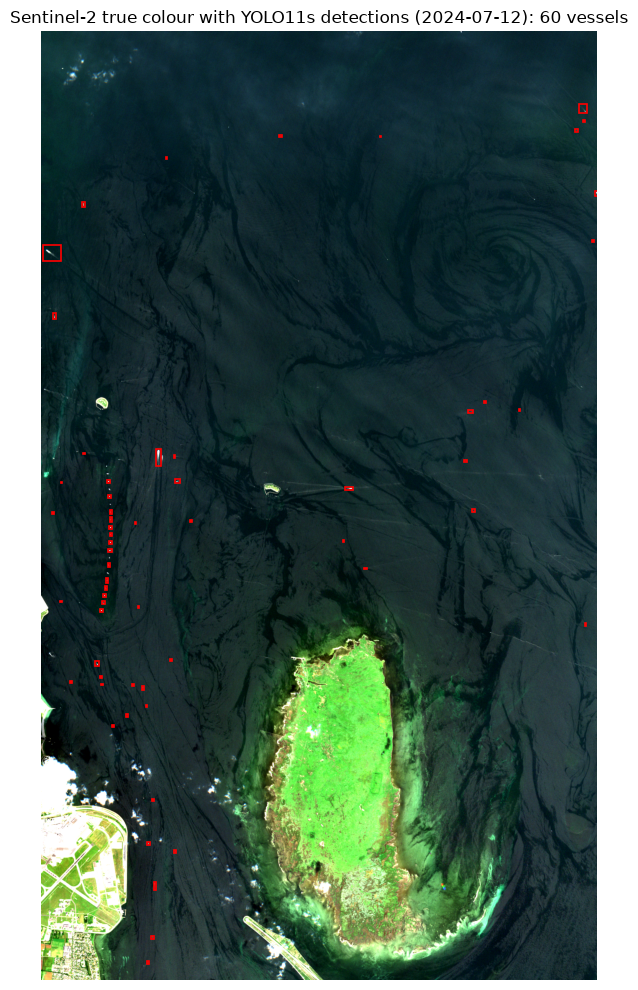

In [5]:
fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(scene.rgb)
for r in out.get("regions", []):
    bb = r["bbox"]
    ax.add_patch(mpatches.Rectangle((bb["x_min"], bb["y_min"]), bb["x_max"] - bb["x_min"],
                                    bb["y_max"] - bb["y_min"], linewidth=1.2,
                                    edgecolor="red", facecolor="none"))
ax.set_title(f"Sentinel-2 true colour with YOLO11s detections ({DATE}): {out['vessel_count']} vessels")
ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Interpretation

Öresund is one of the busiest straits in Northern Europe; the larger ships in the shipping lanes
are the most reliable detections. Fixed structures are detected too: the straight row of boxes west
of Saltholm is the Middelgrunden wind farm (20 turbines), and harbour structures can add more, so
the count is an upper bound to check against AIS.

**Next steps:** a commercial follow-up would combine Sentinel-2 detections with AIS and, for
selected vessels, very-high-resolution imagery under its own licence.

**Links:** [`imint/analyzers/marine_vessels.py`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/blob/b183e1a/imint/analyzers/marine_vessels.py)

## Provenance

The saved outputs were produced by running this notebook top to bottom against IMINT Engine commit [`b183e1a`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/commit/b183e1abd4653cb843a75557b05c09915fb85904) with data from Digital Earth Sweden. Dates are acquisition dates, chosen among the scenes DES holds by the cloud fraction over the area in the scene classification (SCL).